# 04. Comparing ICL and LoRA: results and errors

Final configurations of `01_icl` and `02_lora` on `rand-test` and `freq-test`: scores, significance of the difference,
which senses each method gets wrong, and whether the lemma helps both methods in the same way.
Runs on CPU from `results/` (no model needed). The detailed ICL error analysis is in `01b_icl_error_analysis`.

In [1]:
# Setup: on Colab or Kaggle, clone (or update) the repository so that `src/` is importable; locally, run from the repo root.
import os, sys
REPO_URL = "https://github.com/Alhassliebe/LAB1_classification_with_llms.git"
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
if "google.colab" in sys.modules or ON_KAGGLE:
    REPO_DIR = ("/kaggle/working" if ON_KAGGLE else "/content") + "/LAB1_classification_with_llms"
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
    else:
        !git -C {REPO_DIR} pull -q
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from src.data import SUPERSENSES, get_split, load_data
from src.evaluate import RESULTS_DIR, evaluate, paired_bootstrap, plot_confusion

FIG_DIR = RESULTS_DIR / "figures"
TEST_SPLITS = ["rand-test", "freq-test"]
METHODS = ["icl", "lora"]
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv").drop_duplicates(["method", "config_id", "split"], keep="last")
train_counts = get_split(load_data(), "train")["supersense"].value_counts()

## 1. Final scores

In [3]:
final = metrics[metrics["split"].isin(TEST_SPLITS) & metrics["method"].isin(METHODS)]
final_ids = final.groupby(["split", "method"])["config_id"].last()  # the configuration run on each test set
final.set_index(["split", "method"])[["config_id", "macro_f1_super", "accuracy_super", "macro_f1_hyper",
                                      "accuracy_hyper", "invalid_rate"]].sort_index()

config_id  macro_f1_super  \
split     method                                                     
freq-test icl     en_5shot_similar_nolemma_logprob          0.5188   
          lora                all_generation_lemma          0.6750   
rand-test icl     en_5shot_similar_nolemma_logprob          0.5832   
          lora                all_generation_lemma          0.7187   

                  accuracy_super  macro_f1_hyper  accuracy_hyper  invalid_rate  
split     method                                                                
freq-test icl             0.5233          0.5357          0.6160           0.0  
          lora            0.7022          0.6740          0.7416           0.0  
rand-test icl             0.7168          0.5691          0.7847           0.0  
          lora            0.8201          0.7229          0.8761           0.0

## 2. Is the difference consistent?

Paired bootstrap on each test set: share of resamples where LoRA has a higher macro-F1 than ICL.
Close to 100 % or 0 % means a consistent difference, around 50 % means none.

In [4]:
both = {}
for split in TEST_SPLITS:
    icl, lora = (pd.read_csv(RESULTS_DIR / "predictions" / f"{m}__{final_ids[split, m]}__{split}.csv",
                             keep_default_na=False) for m in METHODS)
    both[split] = icl.merge(lora[["sense_id", "pred_supersense"]], on="sense_id", suffixes=("_icl", "_lora")).assign(
        correct_icl=lambda d: d["pred_supersense_icl"] == d["gold_supersense"],
        correct_lora=lambda d: d["pred_supersense_lora"] == d["gold_supersense"])
    share = paired_bootstrap(both[split]["gold_supersense"], both[split]["pred_supersense_icl"],
                             both[split]["pred_supersense_lora"], SUPERSENSES)
    print(f"{split}: LoRA beats ICL in {share:.0%} of bootstrap resamples")

rand-test: LoRA beats ICL in 100% of bootstrap resamples
freq-test: LoRA beats ICL in 100% of bootstrap resamples


## 3. Do the methods make the same errors?

In [5]:
pd.concat({split: pd.crosstab(d["correct_icl"], d["correct_lora"], normalize="all").round(3)
           for split, d in both.items()})

correct_lora           False  True 
          correct_icl              
rand-test False        0.142  0.142
          True         0.038  0.678
freq-test False        0.242  0.235
          True         0.056  0.467

## 4. Per-class F1

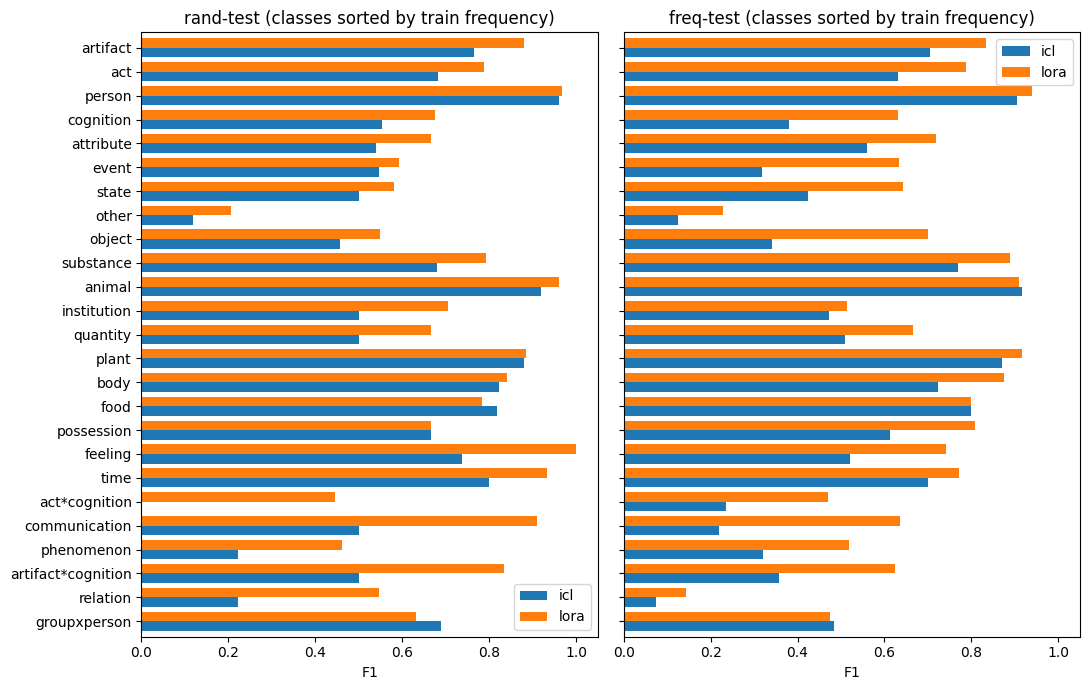

icl   lora  n_test  n_train
rand-test groupxperson        0.690  0.632      13       84
          relation            0.222  0.546       7       98
          artifact*cognition  0.500  0.833      17      102
          phenomenon          0.222  0.462       5      133
          communication       0.500  0.909       6      157
          act*cognition       0.000  0.444       3      161
          time                0.800  0.933       7      186
          feeling             0.737  1.000       8      240
          possession          0.667  0.667       3      242
          food                0.818  0.783       9      318
          body                0.824  0.842       8      320
          plant               0.880  0.885      26      342
          quantity            0.500  0.667      14      343
          institution         0.500  0.706       7      378
          animal              0.920  0.962      26      395
          substance           0.681  0.792      20      411
          object              0.456  0.550      25      416
          other               0.118  0.207      26      426
          state               0.500  0.581      13      427
          event               0.546  0.593      18      461
          attribute           0.540  0.667      19      685
          cognition           0.554  0.676      39      931
          person              0.960  0.967     179      966
          act                 0.681  0.788      54     1123
          artifact            0.765  0.880     126     1259
freq-test groupxperson        0.483  0.474      28       84
          relation            0.074  0.143       2       98
          artifact*cognition  0.357  0.625      37      102
          phenomenon          0.320  0.518       9      133
          communication       0.218  0.636      10      157
          act*cognition       0.235  0.469      46      161
          time                0.700  0.773      19      186
          feeling             0.522  0.741      15      240
          possession          0.612  0.810      22      242
          food                0.800  0.800      14      318
          body                0.722  0.875      17      320
          plant               0.870  0.917      12      342
          quantity            0.509  0.667      47      343
          institution         0.472  0.515      28      378
          animal              0.917  0.909      11      395
          substance           0.769  0.889      21      411
          object              0.341  0.700      39      416
          other               0.124  0.229     163      426
          state               0.423  0.644      73      427
          event               0.319  0.634      36      461
          attribute           0.559  0.718     106      685
          cognition           0.381  0.631     153      931
          person              0.906  0.940      89      966
          act                 0.631  0.787     309     1123
          artifact            0.706  0.833     215     1259

In [6]:
fig, axes = plt.subplots(1, len(TEST_SPLITS), figsize=(11, 7), sharex=True, sharey=True)
per_class = {}
for ax, (split, d) in zip(axes, both.items()):
    per_class[split] = pd.DataFrame({m: evaluate(d["gold_supersense"].tolist(), d[f"pred_supersense_{m}"].tolist(),
                                                 SUPERSENSES)["per_class"] for m in METHODS}).assign(
        n_test=d["gold_supersense"].value_counts(), n_train=train_counts).sort_values("n_train")
    per_class[split][METHODS].plot.barh(ax=ax, width=0.8)
    ax.set_title(f"{split} (classes sorted by train frequency)")
    ax.set_xlabel("F1")
fig.tight_layout()
fig.savefig(FIG_DIR / "per_class_f1_icl_vs_lora.png", dpi=200)
plt.show()
pd.concat(per_class).round(3)

## 5. Confusions of LoRA

ICL confusion matrices are produced by `01b_icl_error_analysis`.

In [7]:
for split, d in both.items():
    plot_confusion(d["gold_supersense"].tolist(), d["pred_supersense_lora"].tolist(), SUPERSENSES,
                   FIG_DIR / f"lora_confusion_{split}.png")
    errors = d[~d["correct_lora"]]
    print(split, ": most frequent LoRA errors (gold, predicted)")
    display(errors.groupby(["gold_supersense", "pred_supersense_lora"]).size().nlargest(10).to_frame("n"))

rand-test : most frequent LoRA errors (gold, predicted)


n
gold_supersense pred_supersense_lora   
groupxperson    person                6
object          substance             6
other           artifact              6
cognition       attribute             5
event           state                 4
object          artifact              4
act             act*cognition         3
                cognition             3
                state                 3
cognition       artifact              3

freq-test : most frequent LoRA errors (gold, predicted)


n
gold_supersense pred_supersense_lora    
other           act                   37
                artifact              28
                institution           26
cognition       attribute             14
groupxperson    institution           14
act*cognition   act                   12
other           cognition             12
act             act*cognition         11
                event                 11
cognition       artifact              11

## 6. Error rate by property of the input

Same shallow cues as in `00_data_exploration` and `01b_icl_error_analysis`.

In [8]:
rows = []
for split, d in both.items():
    props = d.assign(
        length=pd.cut(d["definition"].str.split().str.len(), [-1, 3, 7, 15, 1000], labels=["0-3", "4-7", "8-15", ">15"]),
        demonym=d["definition"].str.match(r"Habitant", case=False),
        synonym_or_variant=d["definition"].str.match(r"(Synonyme|Variante|Autre nom|Pluriel) de", case=False),
        complex_type=d["gold_supersense"].str.contains("*", regex=False))
    rows += [(split, prop, value, len(g), 1 - g["correct_icl"].mean(), 1 - g["correct_lora"].mean())
             for prop in ["length", "demonym", "synonym_or_variant", "complex_type"]
             for value, g in props.groupby(prop, observed=True)]
pd.DataFrame(rows, columns=["split", "property", "value", "n", "error_icl", "error_lora"]).round(3)

,split,property,value,n,error_icl,error_lora
0,rand-test,length,0-3,89,0.393,0.213
1,rand-test,length,4-7,154,0.305,0.182
2,rand-test,length,8-15,288,0.229,0.146
3,rand-test,length,>15,147,0.299,0.224
4,rand-test,demonym,False,565,0.340,0.216
5,rand-test,demonym,True,113,0.000,0.000
6,rand-test,synonym_or_variant,False,647,0.274,0.179
7,rand-test,synonym_or_variant,True,31,0.484,0.194
8,rand-test,complex_type,False,658,0.280,0.181
9,rand-test,complex_type,True,20,0.400,0.150


## 7. Senses that both methods get wrong

In [9]:
pd.set_option("display.max_colwidth", 90)
hard = pd.concat({split: d[~d["correct_icl"] & ~d["correct_lora"]] for split, d in both.items()})
display(hard.groupby("gold_supersense").size().nlargest(10).to_frame("n_both_wrong"))
hard.sample(min(30, len(hard)), random_state=42)[
    ["lemma", "definition", "gold_supersense", "pred_supersense_icl", "pred_supersense_lora"]]

,n_both_wrong
gold_supersense,
other,153
act,67
cognition,59
state,28
act*cognition,24
attribute,16
object,16
event,15
groupxperson,15


lemma  \
rand-test 69         actuaire   
          218        actinide   
          306   multimodalité   
freq-test 1435      rendement   
          740           copie   
          521           repas   
          1395        édition   
          659            zone   
rand-test 591           pièce   
freq-test 1443   civilisation   
          528          taille   
          1230      extension   
          1399        édition   
          1319          poste   
          568           siège   
rand-test 582           pièce   
freq-test 1427        barreau   
          168      continuité   
          595         mariage   
rand-test 16            zéine   
          517       vaisselle   
freq-test 319        possible   
          1472       héritage   
          242    confirmation   
rand-test 611      couverture   
          445         retzite   
          612      couverture   
          595           pièce   
freq-test 504       préjudice   
rand-test 609      couverture   

                                                                                               definition  \
rand-test 69    Écriture latine à lettres étroites et plutôt irrégulières, apparaissant sur des actes ...   
          218   Élément chimique du tableau périodique se situant entre l’actinium et le lawrencium, e...   
          306                       Présence de plusieurs modes de transport différents entre deux lieux.   
freq-test 1435  Rapport entre ce que produit un système industriel, chimique, biologique, etc., à ce q...   
          740                                                         Simple imitation, emprunt, plagiat.   
          521   Nourriture que l’on prend pour s’alimenter pendant une période spécifiquement consacré...   
          1395                                         Tirage spécifique de la même édition d’un ouvrage.   
          659                    Portion de la surface d’une sphère comprise entre deux plans parallèles.   
rand-test 591   Œuvre ou ouvrage de l’esprit, dont chacun fait un tout complet. → voir pièce de théâtr...   
freq-test 1443  Ensemble d’individus ayant en commun des mêmes éléments religieux, culturels, politiqu...   
          528                   Coupe ; manière dont on coupe certaines choses, dont elles sont taillées.   
          1230                                               Augmentation d’un privilège, d’une autorité.   
          1399                              Par extension, émission de télévision donnant les actualités.   
          1319                                                           Fonctions occupées sur ce poste.   
          568                                          Un évêché et sa juridiction. — → voir Saint-Siège.   
rand-test 582                                                                   Contenu d’un tel tonneau.   
freq-test 1427                                                                Ordre ou corps des avocats.   
          168                                              Liaison non interrompue des parties d’un tout.   
          595   Union (reconnue officiellement en tant que mariage) de deux personnes de sexe quelconque.   
rand-test 16                                                                   Protéine extraite du maïs.   
          517                       Objets en métal précieux servant à l’usage de la table d’un seigneur.   
freq-test 319                                                                  Ce qui est en son pouvoir.   
          1472                                         Obtention de propriétés à partir de la roche-mère.   
          242                                                                        Action de confirmer.   
rand-test 611                                                       Ce qui sert à cacher ou à dissimuler.   
          445                                                                       Synonyme de stilbite.   
          612   Fausse identité endossée ponctuellement p

## 8. Does the lemma help both methods?

Every `rand-dev` run without the lemma, next to the same configuration with the lemma.

In [10]:
dev_f1 = metrics[metrics["split"] == "rand-dev"].set_index(["method", "config_id"])["macro_f1_super"]
pd.DataFrame([(m, cid.replace("_nolemma", "_lemma"), dev_f1[m, cid.replace("_nolemma", "_lemma")], f1)
              for (m, cid), f1 in dev_f1.items()
              if "_nolemma" in cid and (m, cid.replace("_nolemma", "_lemma")) in dev_f1.index],
             columns=["method", "config_id", "macro_f1_with_lemma", "macro_f1_without_lemma"])

,method,config_id,macro_f1_with_lemma,macro_f1_without_lemma
0,icl,en_5shot_similar_lemma,0.4757,0.5022
1,lora,all_generation_lemma,0.6699,0.6192
2,camembert,base_lemma,0.5061,0.4828


## Observations

- LoRA is better than the best ICL configuration on both test sets: macro-F1 0.719 vs 0.583 on `rand-test` and
  0.675 vs 0.519 on `freq-test`, in 100 % of bootstrap resamples.
- The errors are nested rather than complementary. On `rand-test`, ICL is right where LoRA is wrong for 3.8 % of the
  senses, the reverse for 14.2 %; on `freq-test`, 5.6 % vs 23.5 %. Both are wrong on 14.2 % and 24.2 % of the senses.
- The largest gains are on rare and abstract classes, e.g. `communication` (F1 0.50 to 0.91 on `rand-test`, 0.22 to
  0.64 on `freq-test`), `artifact*cognition`, `act*cognition`, and on `object`, `event` and `cognition` on
  `freq-test`. LoRA is worse on `groupxperson` on both test sets (F1 0.69 to 0.63 and 0.48 to 0.47), where it
  predicts `person` (`rand-test`) or `institution` (`freq-test`), and slightly worse on `food` (`rand-test`) and
  `animal` (`freq-test`).
- `other` is the hardest class for both methods (LoRA F1 0.21 on `rand-test`, 0.23 on `freq-test`). It covers 163
  of the 1,521 `freq-test` senses and accounts for 153 of the senses that both methods get wrong (both test sets
  together); on `freq-test`, LoRA mostly predicts `act`, `artifact` or `institution` for them. Being a residual class, it has no positive definition the
  model could learn.
- Some inputs no longer cause trouble after fine-tuning: definitions starting with "Synonyme de", "Variante de"...
  (error rate 0.48 for ICL vs 0.19 for LoRA on `rand-test`) and very short definitions (0.39 vs 0.21 for 0 to 3
  words). Demonyms ("Habitant de...", 113 senses of `rand-test`) are always right for both. Complex types such as
  `act*cognition` stay hard on `freq-test` (LoRA error rate 0.53 on 83 senses).
- Near misses: among LoRA's errors, 31 % on `rand-test` and 13 % on `freq-test` stay within the gold hypersense
  (hypersense accuracy 0.876 and 0.742 vs supersense accuracy 0.820 and 0.702).
- The lemma helps LoRA (+0.051 macro-F1 on `rand-dev`) but not ICL (-0.027). One hypothesis: with 10,604 training
  examples the model can learn which lemma forms go with which class, while 5 demonstrations are not enough to do so.